# Ergebnisse

0. Import
1. Datensatz laden
2. Modelle (Entscheidungsbaum, KNN, Logistische Regression, Ensemble)
3. Ergebnisse
   1. Übersicht der Kennzahlen
   2. Konfusionsmatrix
   3. Visuelle Darstellung der Konfusionsmatrix
   4. Fehlertabelle
   5. ROC-Kurven
   6. Zeitmessung / Performance


In [101]:
# Übernahme aller Bibiotheken von Ingride sowie die Codeblöcke

# --- Standard library ---

import random
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf                          
import tensorflow.keras as keras
import pickle

# --- Models ---
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import VotingClassifier

# --- Data splitting ---
from sklearn.model_selection import train_test_split
from sklearn.model_selection import GridSearchCV

# --- Evaluation metrics ---
from sklearn.metrics import accuracy_score
from sklearn.metrics import confusion_matrix
from sklearn.metrics import ConfusionMatrixDisplay
from sklearn.metrics import classification_report
from sklearn.metrics import precision_score
from sklearn.metrics import f1_score
from sklearn.metrics import roc_auc_score
from sklearn.metrics import roc_curve, auc
from sklearn.metrics import recall_score

from sklearn.base import clone 
from sklearn.preprocessing import label_binarize

## 1. Datensatz Laden 

In [108]:
mnist = tf.keras.datasets.mnist
(X_train, y_train), (X_test, y_test) = mnist.load_data()

X_train = X_train / 255.0
X_test = X_test / 255.0

X_train = X_train.reshape(X_train.shape[0], -1)
X_test = X_test.reshape(X_test.shape[0], -1)

## 2. Modelle - (Entscheidungsbaum, KNN, Logistische Regression, Ensamble)

Zusammfassung der Modelle (Quelle: Final_Ensamble_Ingride-Tieleu) + Auswahl des besten Ensamble Ergebnis

In [82]:
# Quelle: Final_Ensamble_Ingride-Tieleu (gekürtzte Version)
# Entscheidungsbaum
# Beste Parameter übernehmen
best_params = {
    'min_samples_split': 2,
    'min_samples_leaf': 2,
    'max_features': None,
    'max_depth': 15,
    'criterion': 'entropy',
    'ccp_alpha': 0.0001
}

# Modell definieren
opt_tree = DecisionTreeClassifier(**best_params, random_state=42)

# Training
opt_tree.fit(X_train, y_train)

# Vorhersagen (Standardisiert)
y_pred_tree = opt_tree.predict(X_test)

# Accuracy 
accuracy_opt = accuracy_score(y_test, y_pred_tree)
print("Entscheidungsbaum Genauigkeit:", round(accuracy_opt, 4))

# Probabilities (für Ensemble)
y_prob_tree = opt_tree.predict_proba(X_test)

# KNN
# Daten vorbereiten (flatten)
X_train_flat = X_train.reshape(X_train.shape[0], -1)
X_test_flat = X_test.reshape(X_test.shape[0], -1)

# Modell definieren
# Bester Wert für k (aus Cross-Validation)
bestes_k = 3

knn_final = KNeighborsClassifier(n_neighbors=bestes_k, n_jobs=-1)

# Training
knn_final.fit(X_train_flat, y_train)

# Vorhersagen (Standardisiert)
y_pred_knn = knn_final.predict(X_test_flat)

# Accuracy
acc_knn = accuracy_score(y_test, y_pred_knn)
print("KNN Genauigkeit:", round(acc_knn, 4))

# Probabilities (für Ensemble)
y_prob_knn = knn_final.predict_proba(X_test_flat)

# Logistische Regression
# Daten vorbereiten

x_train_clean_norm = X_train
x_test_clean_norm = X_test

# GridSearch 
param_grid = {
    'C': [0.01],
    'max_iter': [3000],
    'penalty': ['l2'],
    'tol': [0.0001]
}

clf = LogisticRegression(random_state=42)

grid = GridSearchCV(clf, param_grid=param_grid, cv=3, n_jobs=-1, verbose=1)
grid.fit(x_train_clean_norm, y_train)

# Bestes Modell übernehmen
log_model = LogisticRegression(**grid.best_params_, random_state=42)

# Training
log_model.fit(x_train_clean_norm, y_train)

# Vorhersagen (Standardisiert)
y_pred_log = log_model.predict(x_test_clean_norm)

# Accuracy
acc_log = accuracy_score(y_test, y_pred_log)
print("Logistische Regression Genauigkeit:", round(acc_log, 4))

# Probabilities (für Ensemble)
y_prob_log = log_model.predict_proba(x_test_clean_norm)

# Ensamble
# gleiche Daten für alle Modelle
X_train_ens = X_train.reshape(len(X_train), -1)
X_test_ens = X_test.reshape(len(X_test), -1)

# VotingClassifier definieren (Hard Voting)
voting_clf_hard = VotingClassifier(
    estimators=[
        ('tree', opt_tree),
        ('knn', knn_final),
        ('logreg', log_model)
    ],
    voting='hard'
)

# VotingClassifier definieren (Soft Voting)
voting_clf_soft = VotingClassifier(
    estimators=[
        ('tree', opt_tree),
        ('knn', knn_final),
        ('logreg', log_model)
    ],
    voting='soft',
    weights=[1, 3, 1]   # kNN etwas stärker gewichtet
)

# Modelle trainieren
voting_clf_hard.fit(X_train_ens, y_train)
voting_clf_soft.fit(X_train_ens, y_train)

# Vorhersagen
y_pred_voting_hard = voting_clf_hard.predict(X_test_ens)
y_pred_voting_soft = voting_clf_soft.predict(X_test_ens)

# Wahrscheinlichkeiten nur für Soft Voting
y_prob_voting_soft = voting_clf_soft.predict_proba(X_test_ens)

# Accuracy für beide Ensembles
acc_voting_hard = accuracy_score(y_test, y_pred_voting_hard)
acc_voting_soft = accuracy_score(y_test, y_pred_voting_soft)

print("Genauigkeit VotingClassifier (Hard):", round(acc_voting_hard, 4))
print("Genauigkeit VotingClassifier (Soft):", round(acc_voting_soft, 4))

# besseres Ensemble auswählen
if acc_voting_soft >= acc_voting_hard:
    ensemble_name = "Ensemble (Soft Voting)"
    y_pred_ens = y_pred_voting_soft
    y_prob_ens = y_prob_voting_soft
    acc_ens = acc_voting_soft
else:
    ensemble_name = "Ensemble (Hard Voting)"
    y_pred_ens = y_pred_voting_hard
    y_prob_ens = None   # Hard Voting hat keine predict_proba-Methode
    acc_ens = acc_voting_hard

print("Bestes Ensemble:", ensemble_name, "mit Genauigkeit", round(acc_ens, 4))


Entscheidungsbaum Genauigkeit: 0.8891
KNN Genauigkeit: 0.9705
Fitting 3 folds for each of 1 candidates, totalling 3 fits
Logistische Regression Genauigkeit: 0.9189
Genauigkeit VotingClassifier (Hard): 0.9549
Genauigkeit VotingClassifier (Soft): 0.9722
Bestes Ensemble: Ensemble (Soft Voting) mit Genauigkeit 0.9722


# 3. Ergebnisse

### A - Übersicht Kenzahlen Genauigkeit,Fehlerrate, Präzision, Sensitivität, Spezifität, F1-Maß, ROC-AUC

In [83]:
klassen = np.unique(y_test)
y_test_bin = label_binarize(y_test, classes=klassen)

# Funktion für Spezifität im Mehrklassenfall (Quelle: Googleseach nach Darstellung Spezifizität)
def spezifitaet_macro(y_true, y_pred):
    cm = confusion_matrix(y_true, y_pred)
    spezifitaeten = []

    for i in range(len(cm)):
        tp = cm[i, i]
        fn = cm[i, :].sum() - tp
        fp = cm[:, i].sum() - tp
        tn = cm.sum() - tp - fn - fp

        if (tn + fp) > 0:
            spez = tn / (tn + fp)
            spezifitaeten.append(spez)

    return np.mean(spezifitaeten)

# Genauigkeit (import accuracy_score)
acc_tree = accuracy_score(y_test, y_pred_tree)
acc_knn = accuracy_score(y_test, y_pred_knn)
acc_log = accuracy_score(y_test, y_pred_log)

# Fehlerrate (1 - import accuracy_score)
fehler_tree = 1 - acc_tree
fehler_knn = 1 - acc_knn
fehler_log = 1 - acc_log
fehler_ens = 1 - acc_ens

# Präzision (import precision_score)
prec_tree = precision_score(y_test, y_pred_tree, average="macro", zero_division=0)
prec_knn = precision_score(y_test, y_pred_knn, average="macro", zero_division=0)
prec_log = precision_score(y_test, y_pred_log, average="macro", zero_division=0)
prec_ens = precision_score(y_test, y_pred_ens, average="macro", zero_division=0)

# Sensitivität (import precision_score)
rec_tree = recall_score(y_test, y_pred_tree, average="macro", zero_division=0)
rec_knn = recall_score(y_test, y_pred_knn, average="macro", zero_division=0)
rec_log = recall_score(y_test, y_pred_log, average="macro", zero_division=0)
rec_ens = recall_score(y_test, y_pred_ens, average="macro", zero_division=0)

# Spezifität (import recall_score)
spez_tree = spezifitaet_macro(y_test, y_pred_tree)
spez_knn = spezifitaet_macro(y_test, y_pred_knn)
spez_log = spezifitaet_macro(y_test, y_pred_log)
spez_ens = spezifitaet_macro(y_test, y_pred_ens)

# F1-Maß (import - f1_score)
f1_tree = f1_score(y_test, y_pred_tree, average="macro", zero_division=0)
f1_knn = f1_score(y_test, y_pred_knn, average="macro", zero_division=0)
f1_log = f1_score(y_test, y_pred_log, average="macro", zero_division=0)
f1_ens = f1_score(y_test, y_pred_ens, average="macro", zero_division=0)

# ROC-AUC 
auc_tree = roc_auc_score(y_test_bin, y_prob_tree, multi_class="ovr", average="macro")
auc_knn = roc_auc_score(y_test_bin, y_prob_knn, multi_class="ovr", average="macro")
auc_log = roc_auc_score(y_test_bin, y_prob_log, multi_class="ovr", average="macro")

# Tabelle
tabelle = pd.DataFrame({
    "Modell": ["Decision Tree", "KNN", "LogReg", ensemble_name],
    "Genauigkeit": [acc_tree, acc_knn, acc_log, acc_ens],
    "Fehlerrate": [fehler_tree, fehler_knn, fehler_log, fehler_ens],
    "Präzision": [prec_tree, prec_knn, prec_log, prec_ens],
    "Sensitivität": [rec_tree, rec_knn, rec_log, rec_ens],
    "Spezifität": [spez_tree, spez_knn, spez_log, spez_ens],
    "F1-Maß": [f1_tree, f1_knn, f1_log, f1_ens],
    "ROC-AUC": [auc_tree, auc_knn, auc_log, auc_ens]
})

tabelle = tabelle.round(4)

display(tabelle)

,Modell,Genauigkeit,Fehlerrate,Präzision,Sensitivität,Spezifität,F1-Maß,ROC-AUC
0,Decision Tree,0.8891,0.1109,0.8877,0.8874,0.9877,0.8874,0.9462
1,KNN,0.9705,0.0295,0.9709,0.9701,0.9967,0.9704,0.9930
2,LogReg,0.9189,0.0811,0.9179,0.9179,0.9910,0.9178,0.9935
3,Ensemble (Soft Voting),0.9722,0.0278,0.9724,0.9719,0.9969,0.9721,0.9986


### B - Konfusionsmatrix

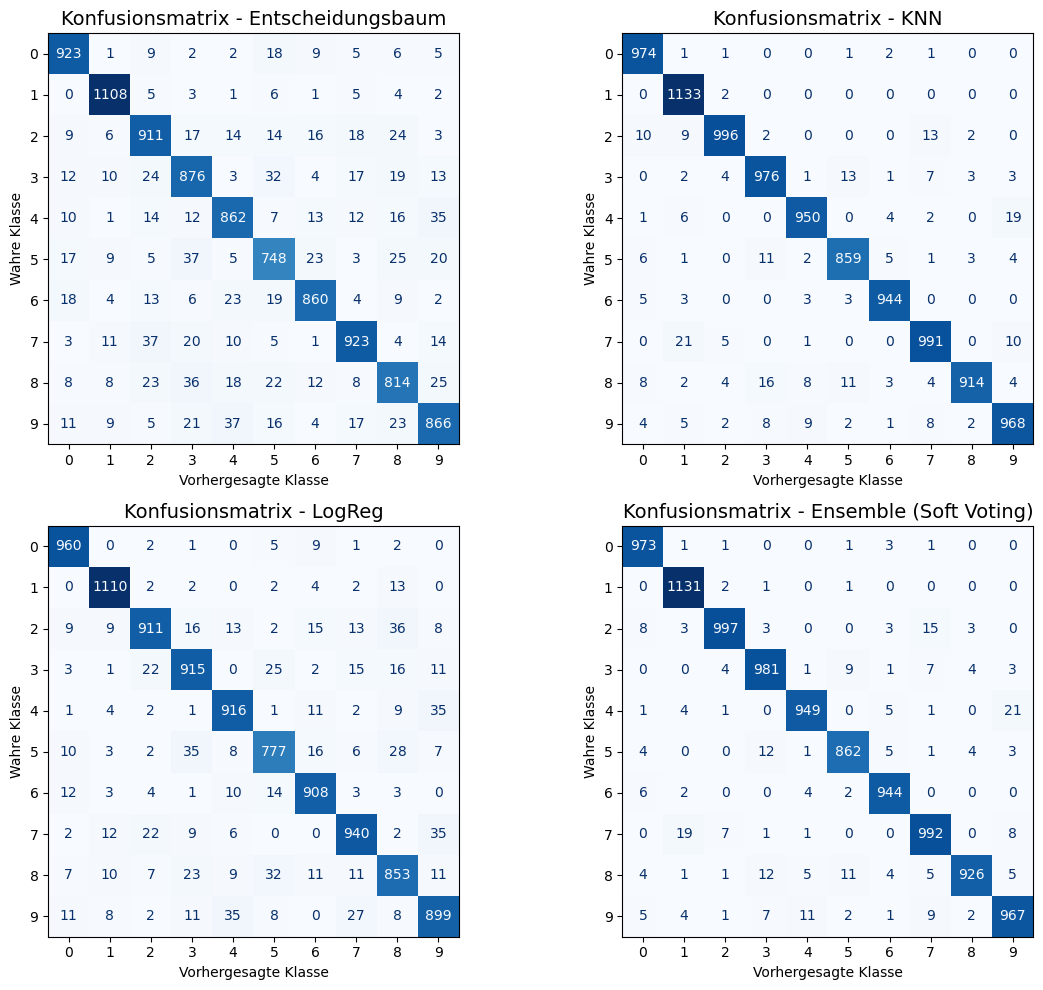

In [98]:
fig, axs = plt.subplots(2, 2, figsize=(12, 10))

klassen = np.unique(y_test)

# Entscheidungsbaum
cm_tree = confusion_matrix(y_test, y_pred_tree)
disp_tree = ConfusionMatrixDisplay(confusion_matrix=cm_tree, display_labels=klassen)
disp_tree.plot(ax=axs[0, 0], cmap="Blues", values_format="d", colorbar=False)
axs[0, 0].set_title("Konfusionsmatrix - Entscheidungsbaum", fontsize=14)
axs[0, 0].set_xlabel("Vorhergesagte Klasse")
axs[0, 0].set_ylabel("Wahre Klasse")

# KNN
cm_knn = confusion_matrix(y_test, y_pred_knn)
disp_knn = ConfusionMatrixDisplay(confusion_matrix=cm_knn, display_labels=klassen)
disp_knn.plot(ax=axs[0, 1], cmap="Blues", values_format="d", colorbar=False)
axs[0, 1].set_title("Konfusionsmatrix - KNN", fontsize=14)
axs[0, 1].set_xlabel("Vorhergesagte Klasse")
axs[0, 1].set_ylabel("Wahre Klasse")

# LogReg
cm_log = confusion_matrix(y_test, y_pred_log)
disp_log = ConfusionMatrixDisplay(confusion_matrix=cm_log, display_labels=klassen)
disp_log.plot(ax=axs[1, 0], cmap="Blues", values_format="d", colorbar=False)
axs[1, 0].set_title("Konfusionsmatrix - LogReg", fontsize=14)
axs[1, 0].set_xlabel("Vorhergesagte Klasse")
axs[1, 0].set_ylabel("Wahre Klasse")

# Ensemble
cm_ens = confusion_matrix(y_test, y_pred_ens)
disp_ens = ConfusionMatrixDisplay(confusion_matrix=cm_ens, display_labels=klassen)
disp_ens.plot(ax=axs[1, 1], cmap="Blues", values_format="d", colorbar=False)
axs[1, 1].set_title(f"Konfusionsmatrix - {ensemble_name}", fontsize=14)
axs[1, 1].set_xlabel("Vorhergesagte Klasse")
axs[1, 1].set_ylabel("Wahre Klasse")

plt.tight_layout()
plt.savefig("Konfussionsmatrix", dpi=300, bbox_inches="tight")
plt.show()

### C - Visuelle Darstellung Konfusionsmatrix

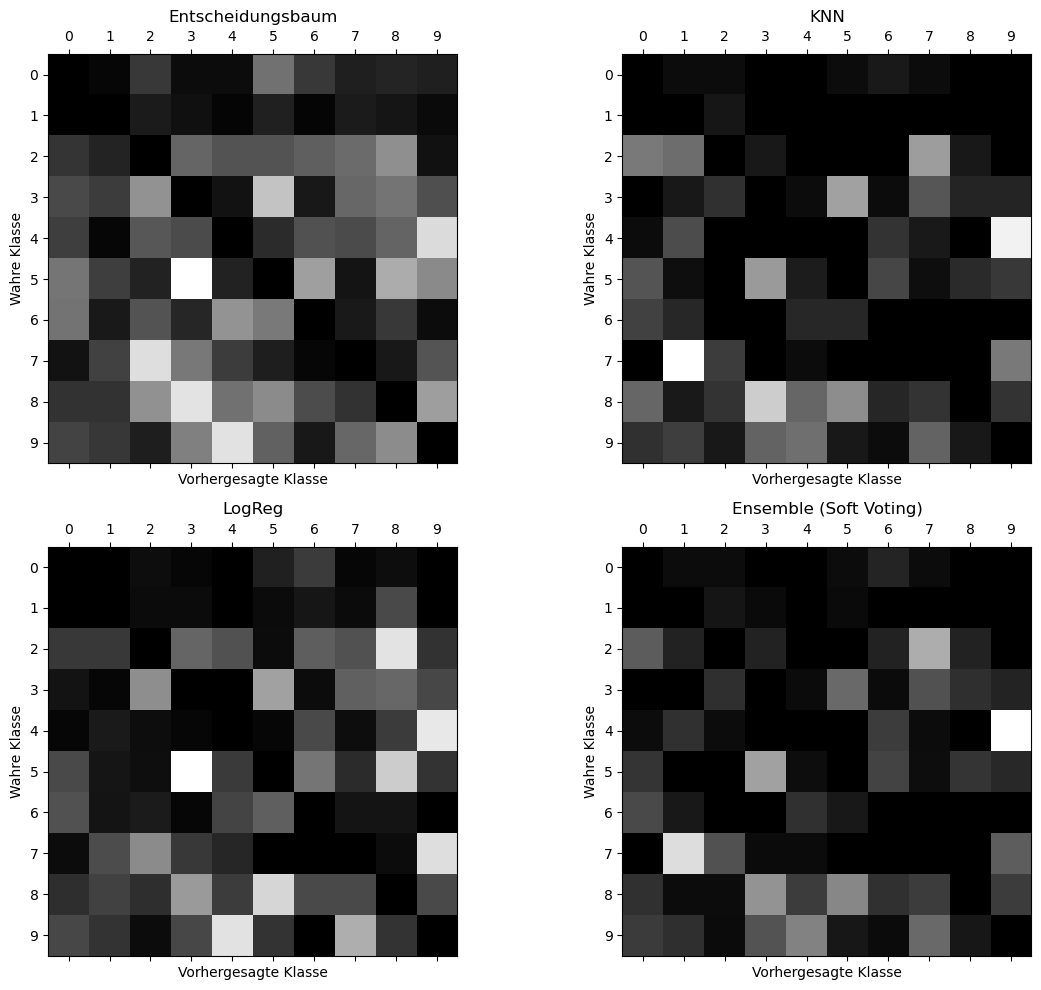

In [112]:
# Quelle: Praxiseinstieg_Machine_Learning_Mit_Scikit-Learn

fig, axs = plt.subplots(2, 2, figsize=(12, 10))

modelle = {
    "Entscheidungsbaum": y_pred_tree,
    "KNN": y_pred_knn,
    "LogReg": y_pred_log,
    ensemble_name: y_pred_ens
}

klassen = np.unique(y_test)
axs = axs.ravel()

for i, (name, y_pred) in enumerate(modelle.items()):
    conf_mx = confusion_matrix(y_test, y_pred)

    row_sums = conf_mx.sum(axis=1, keepdims=True)
    norm_conf_mx = conf_mx / row_sums

    np.fill_diagonal(norm_conf_mx, 0)

    axs[i].matshow(norm_conf_mx, cmap=plt.cm.gray)
    axs[i].set_title(name)
    axs[i].set_xlabel("Vorhergesagte Klasse")
    axs[i].set_ylabel("Wahre Klasse")
    axs[i].set_xticks(range(len(klassen)))
    axs[i].set_yticks(range(len(klassen)))
    axs[i].set_xticklabels(klassen)
    axs[i].set_yticklabels(klassen)

plt.tight_layout()
plt.savefig("Visuelle:Darstellung_Konfussionsmatrix", dpi=300, bbox_inches="tight")
plt.show()

In [90]:
# Quelle: Praxiseinstieg_Machine_Learning_Mit_Scikit-Learn

def erstelle_fehler_tabelle(y_true, y_pred):
    cm = confusion_matrix(y_true, y_pred)

    fehler_liste = []

    for i in range(cm.shape[0]):
        for j in range(cm.shape[1]):
            if i != j and cm[i, j] > 0:
                fehler_liste.append([i, j, cm[i, j]])

    fehler_tabelle = pd.DataFrame(
        fehler_liste,
        columns=["Wahre Ziffer", "Vorhergesagte Ziffer", "Anzahl"]
    )

    fehler_tabelle = fehler_tabelle.sort_values(by="Anzahl", ascending=False)
    return fehler_tabelle

# Fehlertabellen für alle Modelle
fehler_tree = erstelle_fehler_tabelle(y_test, y_pred_tree)
fehler_knn = erstelle_fehler_tabelle(y_test, y_pred_knn)
fehler_log = erstelle_fehler_tabelle(y_test, y_pred_log)
fehler_voting_soft = erstelle_fehler_tabelle(y_test, y_pred_voting_soft)

# Ausgabe der Tabellen
print("Entscheidungsbaum")
display(fehler_tree.head(5))

print("KNN")
display(fehler_knn.head(5))

print("LogReg")
display(fehler_log.head(5))

print("Voting Soft")
display(fehler_voting_soft.head(5))

Entscheidungsbaum


,Wahre Ziffer,Vorhergesagte Ziffer,Anzahl
64,7,2,37
84,9,4,37
47,5,3,37
74,8,3,36
43,4,9,35


KNN


,Wahre Ziffer,Vorhergesagte Ziffer,Anzahl
36,7,1,21
23,4,9,19
43,8,3,16
9,2,7,13
14,3,5,13


LogReg


,Wahre Ziffer,Vorhergesagte Ziffer,Anzahl
19,2,8,36
75,9,4,35
41,5,3,35
61,7,9,35
37,4,9,35


Voting Soft


,Wahre Ziffer,Vorhergesagte Ziffer,Anzahl
26,4,9,21
38,7,1,19
12,2,7,15
46,8,3,12
28,5,3,12


### D - Fehlertabelle

Die Fehlertabell

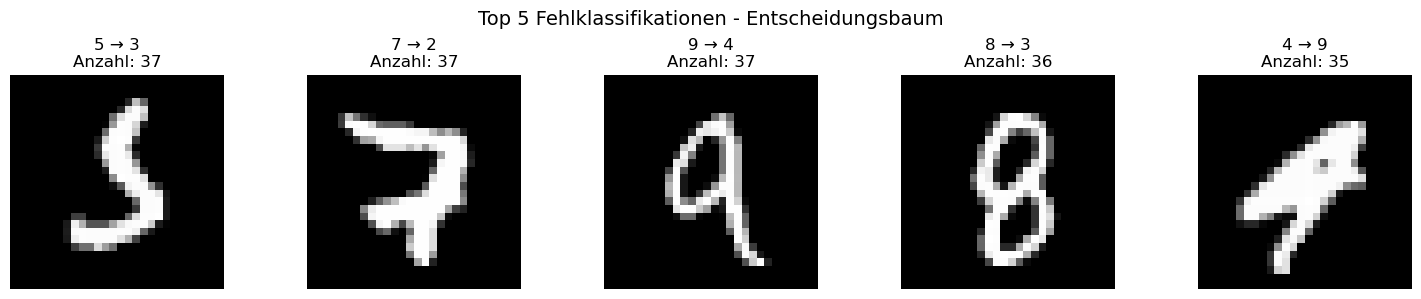

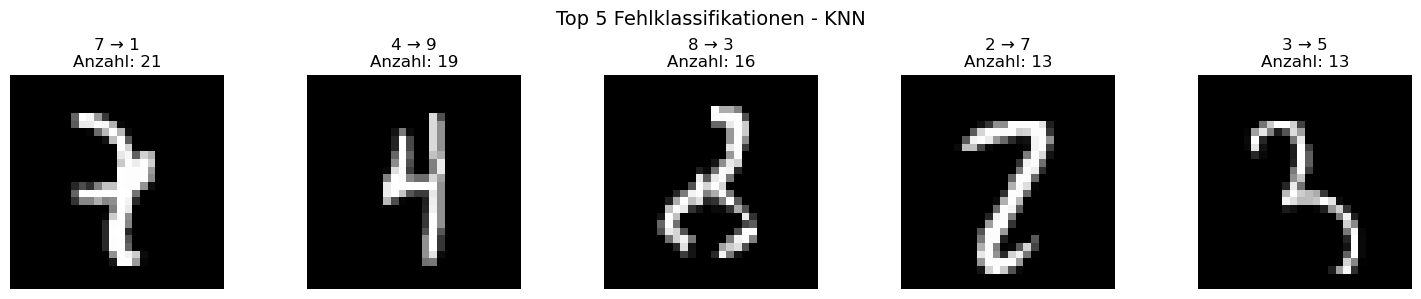

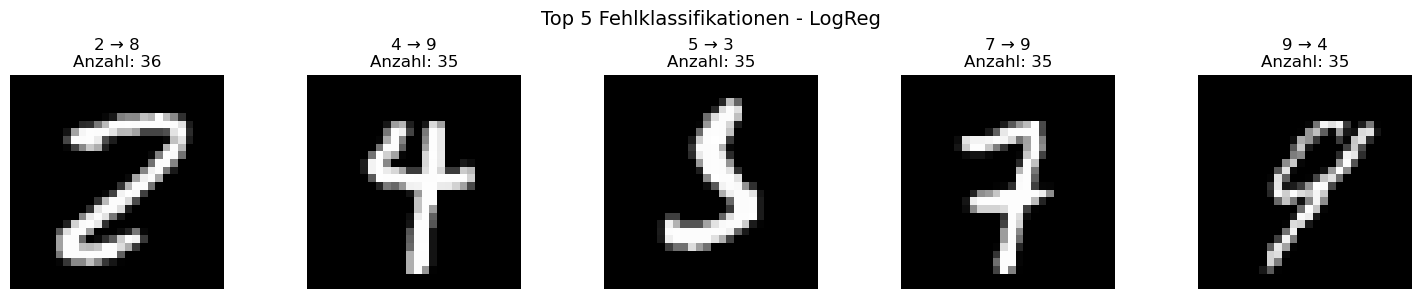

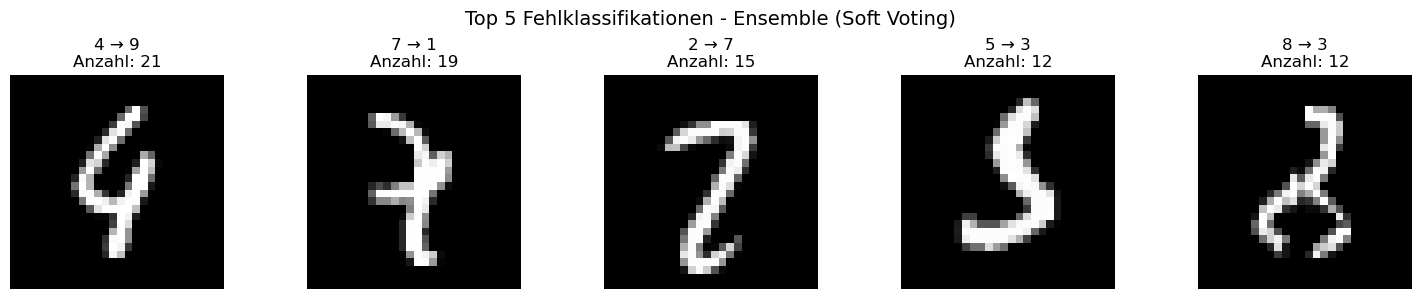

In [96]:
# Visuelle Darstellung der Fehler

def zeige_top5_fehlerbilder(X_bilder, y_true, y_pred, modell_name):
    cm = confusion_matrix(y_true, y_pred)
    fehler_liste = []

    # häufigste Fehlklassifikationen sammeln
    for i in range(cm.shape[0]):
        for j in range(cm.shape[1]):
            if i != j and cm[i, j] > 0:
                fehler_liste.append((i, j, cm[i, j]))

    # nach Häufigkeit sortieren
    fehler_liste = sorted(fehler_liste, key=lambda x: x[2], reverse=True)

    # Top 5 nehmen
    top5 = fehler_liste[:5]

    fig, axs = plt.subplots(1, 5, figsize=(15, 3))
    fig.suptitle(f"Top 5 Fehlklassifikationen - {modell_name}", fontsize=14)

    for k, (wahre_klasse, vorher_klasse, anzahl) in enumerate(top5):
        # erstes passendes falsch klassifiziertes Bild suchen
        idx = np.where((y_true == wahre_klasse) & (y_pred == vorher_klasse))[0][0]

        bild = X_bilder[idx]

        # falls das Bild flach ist, wieder quadratisch machen
        if bild.ndim == 1:
            seite = int(np.sqrt(len(bild)))
            bild = bild.reshape(seite, seite)

        axs[k].imshow(bild, cmap="gray")
        axs[k].set_title(f"{wahre_klasse} → {vorher_klasse}\nAnzahl: {anzahl}")
        axs[k].axis("off")

    plt.tight_layout()
    plt.savefig("top5_fehlerbilder.png", dpi=300, bbox_inches="tight")
    plt.show()


# Modelle durchgehen
modelle = {
    "Entscheidungsbaum": y_pred_tree,
    "KNN": y_pred_knn,
    "LogReg": y_pred_log,
    ensemble_name: y_pred_ens
}

for name, y_pred in modelle.items():
    zeige_top5_fehlerbilder(X_test, y_test, y_pred, name)

### E - ROC-Kurven

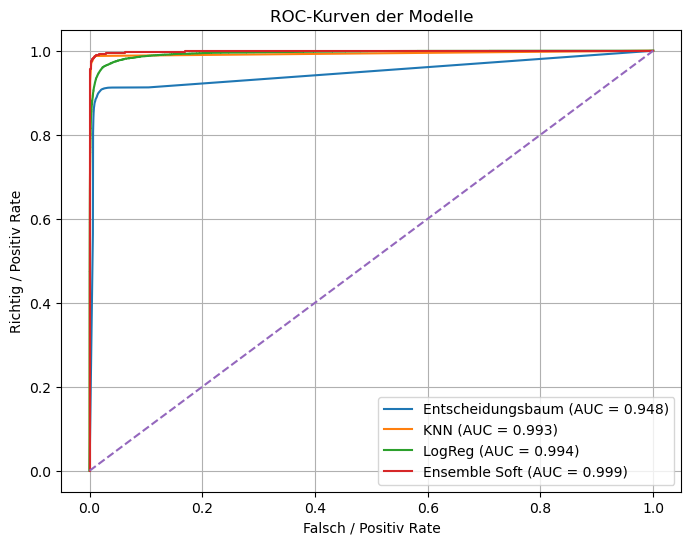

<Figure size 640x480 with 0 Axes>

In [109]:
klassen = np.unique(y_test)
y_test_bin = label_binarize(y_test, classes=klassen)

# Wahrscheinlichkeiten für Soft-Voting-Ensemble
y_prob_ens = voting_clf_soft.predict_proba(X_test_ens)

# ROC-Kurven berechnen
fpr_tree, tpr_tree, _ = roc_curve(y_test_bin.ravel(), y_prob_tree.ravel())
auc_tree = auc(fpr_tree, tpr_tree)

fpr_knn, tpr_knn, _ = roc_curve(y_test_bin.ravel(), y_prob_knn.ravel())
auc_knn = auc(fpr_knn, tpr_knn)

fpr_log, tpr_log, _ = roc_curve(y_test_bin.ravel(), y_prob_log.ravel())
auc_log = auc(fpr_log, tpr_log)

fpr_ens, tpr_ens, _ = roc_curve(y_test_bin.ravel(), y_prob_ens.ravel())
auc_ens = auc(fpr_ens, tpr_ens)

# Plot der Roc-Kurven
plt.figure(figsize=(8, 6))
plt.plot(fpr_tree, tpr_tree, label=f"Entscheidungsbaum (AUC = {auc_tree:.3f})")
plt.plot(fpr_knn, tpr_knn, label=f"KNN (AUC = {auc_knn:.3f})")
plt.plot(fpr_log, tpr_log, label=f"LogReg (AUC = {auc_log:.3f})")
plt.plot(fpr_ens, tpr_ens, label=f"Ensemble Soft (AUC = {auc_ens:.3f})")
plt.plot([0, 1], [0, 1], "--")

plt.xlabel("Falsch / Positiv Rate")
plt.ylabel("Richtig / Positiv Rate")
plt.title("ROC-Kurven der Modelle")
plt.legend()
plt.grid(True)
plt.show()
plt.savefig("ROC Kurve", dpi=300, bbox_inches="tight")

### F - Zeitmessung und Speicherplatznutzung

In [55]:
start = time.perf_counter()
opt_tree.fit(X_train, y_train)
zeit_tree_train = time.perf_counter() - start

start = time.perf_counter()
knn_final.fit(X_train_flat, y_train)
zeit_knn_train = time.perf_counter() - start

start = time.perf_counter()
log_model.fit(x_train_clean_norm, y_train)
zeit_log_train = time.perf_counter() - start

start = time.perf_counter()
voting_clf_soft.fit(X_train, y_train)
zeit_ens_train = time.perf_counter() - start

# Ausgabe der Zeiten
print("Trainingszeiten:")
print("Decision Tree:", round(zeit_tree_train, 4), "Sekunden")
print("KNN:", round(zeit_knn_train, 4), "Sekunden")
print("LogReg:", round(zeit_log_train, 4), "Sekunden")
print("Ensemble:", round(zeit_ens_train, 4), "Sekunden")

Trainingszeiten:
Decision Tree: 10.2099 Sekunden
KNN: 0.0151 Sekunden
LogReg: 7.2944 Sekunden
Ensemble: 19.179 Sekunden


In [64]:
# Funktion zum Zeit messn
def messe_zeiten(modell, X_train_daten, X_test_daten, y_train):
    modell_kopie = clone(modell)

    # Trainingszeit messen
    start = time.perf_counter()
    modell_kopie.fit(X_train_daten, y_train)
    train_zeit = time.perf_counter() - start

    # Klassifizierungszeit auf Trainingsdaten messen
    start = time.perf_counter()
    modell_kopie.predict(X_train_daten)
    pred_train_zeit = time.perf_counter() - start

    # Klassifizierungszeit auf Testdaten messen
    start = time.perf_counter()
    modell_kopie.predict(X_test_daten)
    pred_test_zeit = time.perf_counter() - start

    return train_zeit, pred_train_zeit, pred_test_zeit


ergebnisse = []

# Entscheidungsbaum
zeit_tree_train, zeit_tree_pred_train, zeit_tree_pred_test = messe_zeiten(
    opt_tree, X_train, X_test, y_train
)
ergebnisse.append([
    "Entscheidungsbaum",
    zeit_tree_train,
    zeit_tree_pred_train,
    zeit_tree_pred_test
])

# KNN
zeit_knn_train, zeit_knn_pred_train, zeit_knn_pred_test = messe_zeiten(
    knn_final, X_train_flat, X_test_flat, y_train
)
ergebnisse.append([
    "KNN",
    zeit_knn_train,
    zeit_knn_pred_train,
    zeit_knn_pred_test
])

# Logistische Regression
zeit_log_train, zeit_log_pred_train, zeit_log_pred_test = messe_zeiten(
    log_model, x_train_clean_norm, x_test_clean_norm, y_train
)
ergebnisse.append([
    "LogReg",
    zeit_log_train,
    zeit_log_pred_train,
    zeit_log_pred_test
])

# Ensemble
zeit_ens_train, zeit_ens_pred_train, zeit_ens_pred_test = messe_zeiten(
    voting_clf_soft, X_train_ens, X_test_ens, y_train
)
ergebnisse.append([
    "Ensemble Soft",
    zeit_ens_train,
    zeit_ens_pred_train,
    zeit_ens_pred_test
])

# Tabelle
zeit_tabelle = pd.DataFrame(
    ergebnisse,
    columns=[
        "Modell",
        "Trainingszeit (s)",
        "Klassifizierungszeit Training (s)",
        "Klassifizierungszeit Test (s)"
    ]
)

zeit_tabelle = zeit_tabelle.round(6)

# Ausgabe der Tabelle
display(zeit_tabelle)

,Modell,Trainingszeit (s),Klassifizierungszeit Training (s),Klassifizierungszeit Test (s)
0,Entscheidungsbaum,10.214478,0.049516,0.006592
1,KNN,0.015232,15.226089,2.548941
2,LogReg,29.100097,0.021177,0.077575
3,Ensemble Soft,19.708236,15.853151,2.771527


In [110]:
def speicherbedarf_modell_mb(modell):
    groesse_bytes = len(pickle.dumps(modell))
    groesse_mb = groesse_bytes / (1024 * 1024)
    return groesse_mb

modelle = {
    "Entscheidungsbaum": opt_tree,
    "KNN": knn_final,
    "LogReg": log_model,
    ensemble_name: voting_clf_soft   # oder y_pred_ens-Modellname passend einsetzen
}

speicher_liste = []

for name, modell in modelle.items():
    groesse_mb = speicherbedarf_modell_mb(modell)
    speicher_liste.append([name, groesse_mb])

speicher_tabelle = pd.DataFrame(
    speicher_liste,
    columns=["Modell", "Speicherbedarf (MB)"]
)

speicher_tabelle["Speicherbedarf (MB)"] = speicher_tabelle["Speicherbedarf (MB)"].round(4)

display(speicher_tabelle)

,Modell,Speicherbedarf (MB)
0,Entscheidungsbaum,0.5588
1,KNN,359.3452
2,LogReg,0.0606
3,Ensemble (Soft Voting),719.9275


### Ergebnis:

Das Ensemble besitzt die höchste Genauigkeit und damit im Vergleich zu den anderen drei Methoden die geringste Fehlerrate.
Auch bei allen weiteren Kennzahlen (Präzision, Sensitivität, Spezifität und F1-Maß) ist das Ensemble den anderen Modellen überlegen.
Das KNN-Modell weist nur eine geringfügig niedrigere Genauigkeit als das Ensemble auf und benötigt eine sehr kurze Trainingszeit. Zudem ist das Modell weniger komplex als das Ensemble. Bei der Anwendung ist KNN jedoch nahezu identisch zum Ensemble.
Sehr Auffällig ist allerdings die unterscheidliche Speichernutzung der Modelle. Während de Entscheidungsbaum und Logistischre Regression nur die gerlernten, gewichtetetn  Parameter speichert sow sieht man bei der KNN Methode, dass dieser den gesamten Trainingsdatensatz abspeichert (470 MB).
Da das Ensemble benötigt den doppelten Speicherplatz da es zum den KNN Klassifizierer enthält und weil bei dem voring_clf_flat die Daten nochmal kopiert werden. Dies könnte man bei einer Optimierung wahrscheinlich umgehen und nur einem den Traingsdatensatz verwenden.

### Fazit:
KNN stellt einen guten Kompromiss zwischen hoher Genauigkeit, geringer Trainingszeit und Einfachheit dar, jedoch wird viel Speicherplatz benötigt.
Für eine schnelle Beurteilung des Datensatzes können auch die logistische Regression und der Entscheidungsbaum genutzt werden, da hier die Klassifizierungszeit sehr kurz ist.
Wie zu erwarten, vereint das Ensemble die Stärken der einzelnen Methoden, was dazu führt, dass es die besten Ergebnisse liefert, allerdings auch den höchsten Zeitbedarf und die größte Modellkomplexität aufweist.
Potentiel für Optimierung beim Ensemble besteht vor allem in der Nutzung des Speicherplatzes